# My Notebook - Quant

In [2]:
%pip install yfinance statsmodels scipy -q

Note: you may need to restart the kernel to use updated packages.


[*********************100%***********************]  2 of 2 completed


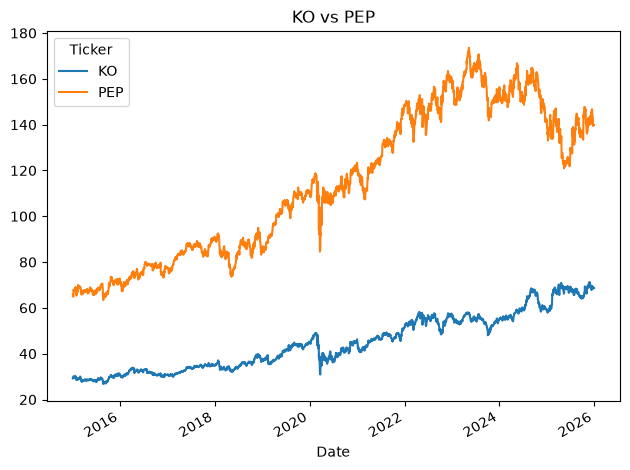

In [3]:
import os, random
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
from scipy.stats import binomtest, mannwhitneyu

PROJECT = os.path.expanduser("~/Documents/ko-pep-stat-arb")
FIG_DIR = os.path.join(PROJECT, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")

# Phase 1 data: KO and PEP only, through 2025
prices = yf.download(["KO", "PEP"], start="2015-01-01", end="2025-12-31",
                     auto_adjust=True)["Close"].dropna()
formation = prices.loc[:"2021-12-31"]
trading = prices.loc["2022-01-01":]

prices.plot(title="KO vs PEP"); save_fig("prices_ko_pep"); plt.show()

In [4]:
print("Correlation:", formation["KO"].corr(formation["PEP"]))
t_stat, p_value, _ = coint(formation["KO"], formation["PEP"])
print("Cointegration p-value (formation):", p_value)

model = sm.OLS(formation["KO"], sm.add_constant(formation["PEP"])).fit()
beta = model.params["PEP"]
print("Hedge ratio (beta):", beta)

print("Out-of-sample cointegration p-value:", coint(trading["KO"], trading["PEP"])[1])

Correlation: 0.9619258540357459
Cointegration p-value (formation): 0.024396025554786732
Hedge ratio (beta): 0.2935014482541676
Out-of-sample cointegration p-value: 0.19008637914106125


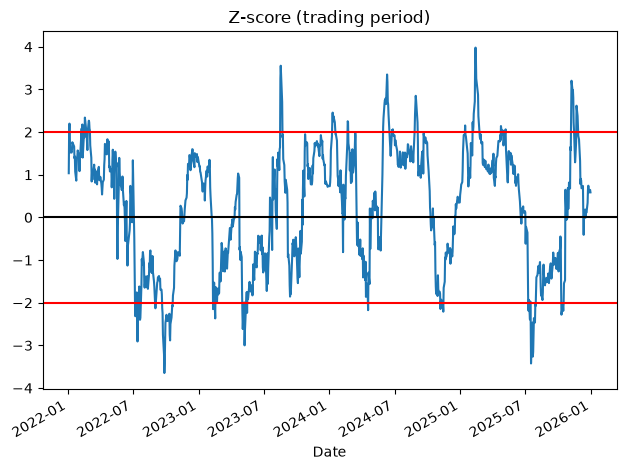

In [5]:
spread = prices["KO"] - beta * prices["PEP"]
window = 60
z = (spread - spread.rolling(window).mean()) / spread.rolling(window).std()

z.loc[trading.index].plot(title="Z-score (trading period)")
plt.axhline(2, color="r"); plt.axhline(-2, color="r"); plt.axhline(0, color="k")
save_fig("zscore_trading_period"); plt.show()

Sharpe: -0.72
Total return: -0.163
Max drawdown: -0.204
Number of trades: 13


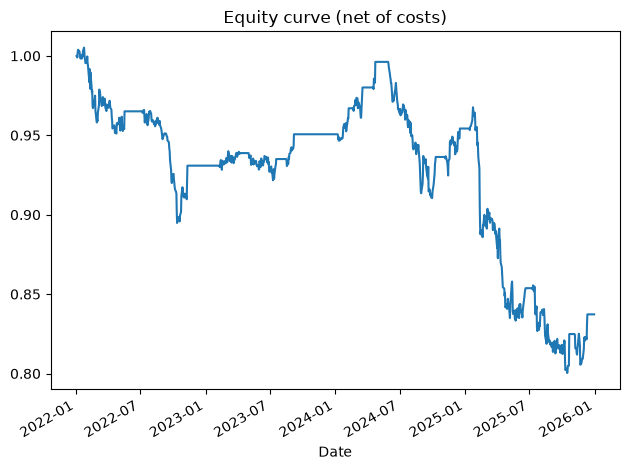

In [6]:
entry, exit_, stop = 2.0, 0.0, 4.0
z_t = z.loc[trading.index]

position = pd.Series(0.0, index=z_t.index)
current = 0
for i in range(len(z_t)):
    zi = z_t.iloc[i]
    if np.isnan(zi):
        position.iloc[i] = 0
        continue
    if current == 0:
        if zi < -entry: current = 1
        elif zi > entry: current = -1
    elif current == 1:
        if zi >= exit_ or zi < -stop: current = 0
    elif current == -1:
        if zi <= exit_ or zi > stop: current = 0
    position.iloc[i] = current

pos_lagged = position.shift(1).fillna(0)
d_spread = (prices["KO"] - beta * prices["PEP"]).diff().loc[trading.index]
pnl = pos_lagged * d_spread

notional = prices["KO"].loc[trading.index] + beta * prices["PEP"].loc[trading.index]
cost = position.diff().abs().fillna(0) * notional * 0.0010
net_pnl = pnl - cost
ret1 = net_pnl / notional.shift(1).bfill()

sharpe = ret1.mean() / ret1.std() * np.sqrt(252)
equity = (1 + ret1).cumprod()
drawdown = equity / equity.cummax() - 1

print("Sharpe:", round(sharpe, 2))
print("Total return:", round(equity.iloc[-1] - 1, 3))
print("Max drawdown:", round(drawdown.min(), 3))
print("Number of trades:", int((position.diff().abs() > 0).sum() / 2))

equity.plot(title="Equity curve (net of costs)")
save_fig("phase1_equity_curve"); plt.show()

Gross total return: -0.141
Net total return:   -0.163
          start        end  days  side        pnl
tid                                              
11.0 2025-01-15 2025-06-20   108  -1.0 -11.181173
9.0  2024-05-31 2024-10-10    92  -1.0  -6.453056
12.0 2025-07-11 2025-10-21    72   1.0  -3.378145
2.0  2022-07-11 2022-11-11    89   1.0  -3.189337
1.0  2022-01-06 2022-05-18    92  -1.0  -3.144703
4.0  2023-05-04 2023-07-19    52   1.0  -0.296618
3.0  2023-02-13 2023-04-10    39   1.0   0.953247
7.0  2024-02-22 2024-03-18    18  -1.0   1.471513
5.0  2023-08-18 2023-09-07    14  -1.0   1.763841
8.0  2024-04-19 2024-04-23     3   1.0   1.790810
6.0  2024-01-10 2024-02-08    21  -1.0   1.828521
13.0 2025-11-07 2025-12-11    24  -1.0   1.883643
10.0 2024-11-07 2024-12-17    28   1.0   2.034195


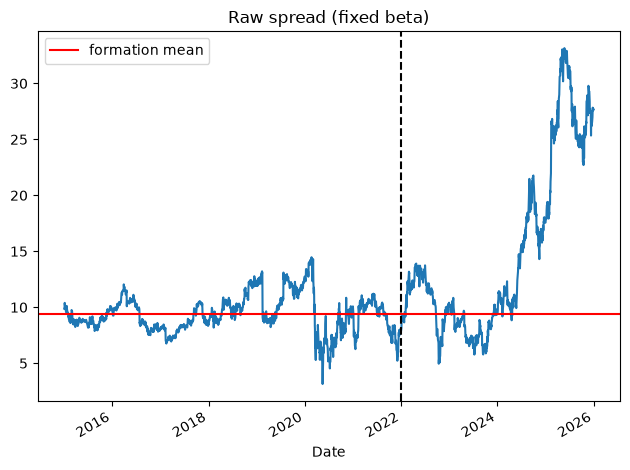

In [7]:
gross_ret = pnl / notional.shift(1).bfill()
print("Gross total return:", round((1 + gross_ret).cumprod().iloc[-1] - 1, 3))
print("Net total return:  ", round(equity.iloc[-1] - 1, 3))

active = pos_lagged != 0
new = active & (pos_lagged.shift(1).fillna(0) == 0)
tid = new.cumsum().where(active)
tlog = pd.DataFrame({"pnl": net_pnl, "side": pos_lagged, "tid": tid}).dropna(subset=["tid"])
trades = tlog.groupby("tid").agg(
    start=("pnl", lambda s: s.index[0]),
    end=("pnl", lambda s: s.index[-1]),
    days=("pnl", "size"),
    side=("side", "first"),
    pnl=("pnl", "sum"),
)
print(trades.sort_values("pnl"))

raw_spread = prices["KO"] - beta * prices["PEP"]
raw_spread.plot(title="Raw spread (fixed beta)")
plt.axhline(raw_spread.loc[:"2021-12-31"].mean(), color="r", label="formation mean")
plt.axvline(pd.Timestamp("2022-01-01"), color="k", ls="--"); plt.legend()
save_fig("raw_spread"); plt.show()

In [8]:
s = formation["KO"] - beta * formation["PEP"]
res_hl = sm.OLS(s.diff().dropna(), sm.add_constant(s.shift(1).dropna())).fit()
lam = res_hl.params.iloc[1]
print("Mean-reversion coefficient:", round(lam, 4))
print("Half-life (trading days):", round(-np.log(2) / lam, 1))

Mean-reversion coefficient: -0.0159
Half-life (trading days): 43.6


In [9]:
def estimate(la, lb):
    beta = sm.OLS(la, sm.add_constant(lb)).fit().params.iloc[1]
    spread = la - beta * lb
    p = coint(la, lb)[1]
    lag, d = spread.shift(1).dropna(), spread.diff().dropna()
    lam = sm.OLS(d, sm.add_constant(lag)).fit().params.iloc[1]
    hl = -np.log(2) / lam if lam < 0 else np.inf
    return beta, spread.mean(), spread.std(), p, hl

def walk_forward(prices, a, b, lookback=504, rebalance=21, p_max=0.05,
                 hl_max=120, entry=2.0, stop=4.0, time_mult=2.0, cost_bps=10):
    la, lb = np.log(prices[a]), np.log(prices[b])
    ra, rb = prices[a].pct_change(), prices[b].pct_change()
    n = len(prices)
    pos, beta_h = np.zeros(n), np.full(n, np.nan)
    current, params, gate = 0, None, False
    trade = None

    for i in range(lookback, n):
        if (i - lookback) % rebalance == 0:
            w = slice(i - lookback, i + 1)
            params = estimate(la.iloc[w], lb.iloc[w])
            beta, mu, sd, p, hl = params
            gate = (p < p_max) and (0 < hl < hl_max)

        if current != 0:
            bt, mt, st, ei, mh = trade
            zz = (la.iloc[i] - bt * lb.iloc[i] - mt) / st
            done = ((current == 1 and zz >= 0) or (current == -1 and zz <= 0)
                    or abs(zz) > stop or (i - ei) >= mh or not gate)
            if done:
                current, trade = 0, None
        elif gate:
            beta, mu, sd, p, hl = params
            zz = (la.iloc[i] - beta * lb.iloc[i] - mu) / sd
            if abs(zz) > entry:
                current = 1 if zz < 0 else -1
                trade = (beta, mu, sd, i, int(time_mult * hl))

        pos[i] = current
        if current != 0:
            beta_h[i] = trade[0]

    pos, bh = pd.Series(pos, prices.index), pd.Series(beta_h, prices.index)
    gross = (pos.shift(1) * (ra - bh.shift(1) * rb) / (1 + bh.shift(1))).fillna(0)
    cost = pos.diff().abs().fillna(0) * cost_bps / 1e4
    ret = (gross - cost).loc[prices.index[lookback]:]
    return ret, pos

def report(ret, pos, label=""):
    eq = (1 + ret).cumprod()
    sharpe = ret.mean() / ret.std() * np.sqrt(252) if ret.std() > 0 else np.nan
    print(f"{label:10s} Sharpe {sharpe:5.2f} | return {eq.iloc[-1]-1:7.1%} | "
          f"maxDD {(eq/eq.cummax()-1).min():7.1%} | "
          f"trades {int((pos.diff().abs()>0).sum()//2):3d} | "
          f"in market {(pos!=0).mean():.0%}")
    return eq

KO/PEP     Sharpe   nan | return    0.0% | maxDD    0.0% | trades   0 | in market 0%
Windows tested:         108
Share with p < 0.05:    0.02
Share with 0<hl<120:    0.93
Share passing both:     0.02
Min p-value:            0.016


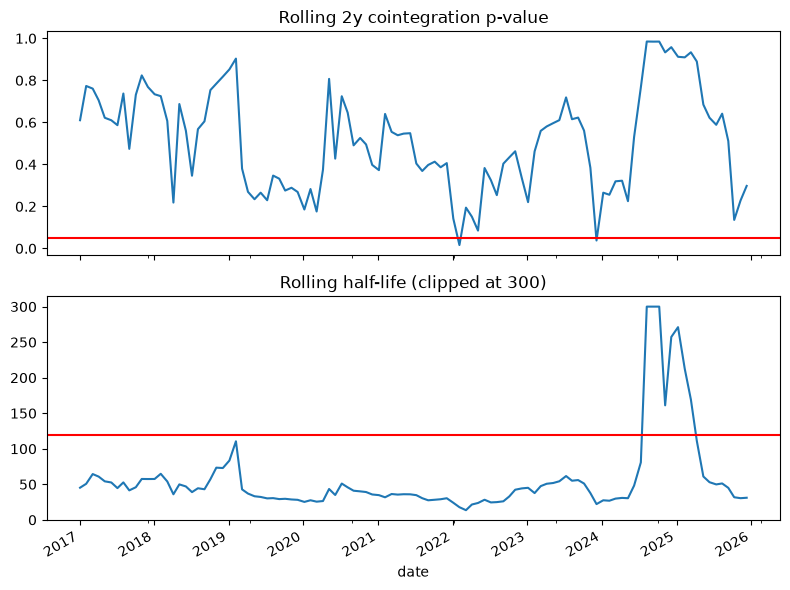

In [10]:
r_kp, p_kp = walk_forward(prices, "KO", "PEP")   # lookback 504
report(r_kp, p_kp, "KO/PEP")

def gate_diagnostics(prices, a, b, lookback=504, rebalance=21):
    la, lb = np.log(prices[a]), np.log(prices[b])
    rows = []
    for i in range(lookback, len(prices), rebalance):
        w = slice(i - lookback, i + 1)
        beta_, mu_, sd_, p_, hl_ = estimate(la.iloc[w], lb.iloc[w])
        zz = (la.iloc[i] - beta_ * lb.iloc[i] - mu_) / sd_
        rows.append((prices.index[i], beta_, p_, hl_, zz))
    return pd.DataFrame(rows, columns=["date", "beta", "p", "hl", "z"]).set_index("date")

d = gate_diagnostics(prices, "KO", "PEP")
print("Windows tested:        ", len(d))
print("Share with p < 0.05:   ", round((d.p < 0.05).mean(), 2))
print("Share with 0<hl<120:   ", round(((d.hl > 0) & (d.hl < 120)).mean(), 2))
print("Share passing both:    ", round(((d.p < 0.05) & (d.hl > 0) & (d.hl < 120)).mean(), 2))
print("Min p-value:           ", round(d.p.min(), 3))

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
d.p.plot(ax=ax[0], title="Rolling 2y cointegration p-value"); ax[0].axhline(0.05, color="r")
d.hl.clip(upper=300).plot(ax=ax[1], title="Rolling half-life (clipped at 300)"); ax[1].axhline(120, color="r")
save_fig("rolling_gate_diagnostics"); plt.show()

In [11]:
sectors = {
    "staples":    ["KO","PEP","PG","CL","KMB","GIS","MDLZ","MO","PM","KR","WMT","COST"],
    "financials": ["JPM","BAC","C","WFC","GS","MS","USB","PNC","V","MA","AXP"],
    "energy":     ["XOM","CVX","COP","EOG","SLB","OXY","MPC","PSX","VLO"],
}
quota = {"staples": 9, "financials": 8, "energy": 8}

tickers = sorted({t for v in sectors.values() for t in v})
px_all = yf.download(tickers, start="2015-01-01", end="2026-11-27", auto_adjust=True)["Close"].dropna()
px = px_all.loc[:"2025-12-31"]          # development + holdout data
print("Price data:", px.shape, "| through 2026:", px_all.shape)

sel_rets = np.log(px.loc[:"2017-12-31"]).diff().dropna()
rows = []
for sec, tk in sectors.items():
    cands = [(a, b, sel_rets[a].corr(sel_rets[b])) for a, b in combinations(tk, 2)]
    for a, b, c in sorted(cands, key=lambda x: -x[2])[:quota[sec]]:
        rows.append((sec, a, b, c))
pairs_df = pd.DataFrame(rows, columns=["sector", "a", "b", "corr"])
print(pairs_df.to_string(index=False))

[*********************100%***********************]  32 of 32 completed

Price data: (2766, 32) | through 2026: (2993, 32)
    sector   a    b     corr
   staples  KO  PEP 0.758513
   staples  CL  KMB 0.682283
   staples  PG   CL 0.663596
   staples PEP   CL 0.657636
   staples PEP   PG 0.641480
   staples GIS MDLZ 0.634487
   staples PEP   PM 0.632687
   staples  MO   PM 0.629655
   staples  PG  KMB 0.621828
financials JPM    C 0.898474
financials BAC    C 0.896838
financials USB  PNC 0.891625
financials JPM  BAC 0.889659
financials JPM  USB 0.874583
financials  GS   MS 0.873900
financials JPM  PNC 0.866551
financials   C   MS 0.865389
    energy XOM  CVX 0.790337
    energy MPC  VLO 0.768570
    energy COP  EOG 0.766241
    energy EOG  OXY 0.738834
    energy CVX  COP 0.723868
    energy COP  OXY 0.723597
    energy CVX  OXY 0.723175
    energy CVX  EOG 0.709976


In [14]:
LOOKBACK = 756
SPLIT = "2021-01-01"

def stats(ret, pos):
    sd = ret.std()
    sharpe = ret.mean() / sd * np.sqrt(252) if sd > 0 else np.nan
    eq = (1 + ret).cumprod()
    return dict(sharpe=sharpe, ret=eq.iloc[-1] - 1,
                maxdd=(eq / eq.cummax() - 1).min(),
                trades=int((pos.loc[ret.index].diff().abs() > 0).sum() // 2),
                in_mkt=(pos.loc[ret.index] != 0).mean())

rows, all_rets = [], {}
for r in pairs_df.itertuples():
    name = f"{r.a}/{r.b}"
    ret, pos = walk_forward(px, r.a, r.b, lookback=LOOKBACK)
    all_rets[name] = ret
    dev, hold = ret.loc[:SPLIT].iloc[:-1], ret.loc[SPLIT:]
    sd_, sh_ = stats(dev, pos), stats(hold, pos)
    rows.append(dict(pair=name, sector=r.sector,
                     dev_sharpe=sd_["sharpe"], dev_trades=sd_["trades"],
                     hold_sharpe=sh_["sharpe"], hold_ret=sh_["ret"],
                     hold_maxdd=sh_["maxdd"], hold_trades=sh_["trades"],
                     hold_in_mkt=sh_["in_mkt"]))

res = pd.DataFrame(rows).set_index("pair")
res.to_csv(os.path.join(PROJECT, "pair_scan_results.csv"))
print(res.round(2).to_string())

              sector  dev_sharpe  dev_trades  hold_sharpe  hold_ret  hold_maxdd  hold_trades  hold_in_mkt
pair                                                                                                     
KO/PEP       staples         NaN           0          NaN      0.00        0.00            0         0.00
CL/KMB       staples         NaN           0         0.11      0.01       -0.05            5         0.03
PG/CL        staples         NaN           0          NaN      0.00        0.00            0         0.00
PEP/CL       staples         NaN           0          NaN      0.00        0.00            0         0.00
PEP/PG       staples       -0.06           2          NaN      0.00        0.00            0         0.00
GIS/MDLZ     staples         NaN           0          NaN      0.00        0.00            0         0.00
PEP/PM       staples         NaN           0          NaN      0.00        0.00            0         0.00
MO/PM        staples         NaN           0  


Holdout (2021+): 10 of 25 pairs traded at least once
Pairs with >=5 trades: 3
Median Sharpe (traded pairs): 0.10
Mean Sharpe   (traded pairs): 0.01
Best / worst Sharpe: 0.80 / -0.78
Positive Sharpe: 6 of 10  (sign-test p vs 50/50: 0.75)
Dev 2018-2020  portfolio Sharpe -0.15 | return  -0.2% | maxDD  -1.0%
Holdout 2021+  portfolio Sharpe  0.24 | return   0.5% | maxDD  -1.0%


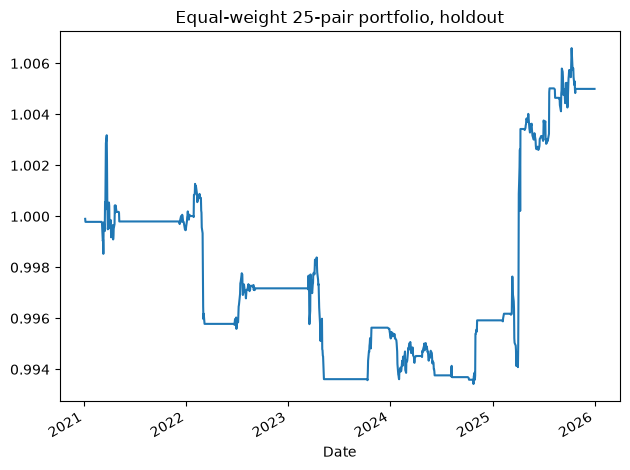

In [15]:
h = res[res.hold_trades > 0]
print(f"\nHoldout (2021+): {len(h)} of {len(res)} pairs traded at least once")
print(f"Pairs with >=5 trades: {(res.hold_trades >= 5).sum()}")
print(f"Median Sharpe (traded pairs): {h.hold_sharpe.median():.2f}")
print(f"Mean Sharpe   (traded pairs): {h.hold_sharpe.mean():.2f}")
print(f"Best / worst Sharpe: {h.hold_sharpe.max():.2f} / {h.hold_sharpe.min():.2f}")
pos_n = int((h.hold_sharpe > 0).sum())
print(f"Positive Sharpe: {pos_n} of {len(h)}  (sign-test p vs 50/50: {binomtest(pos_n, len(h), 0.5).pvalue:.2f})")

R = pd.DataFrame(all_rets).fillna(0)
port = R.mean(axis=1)
for label, s_ in [("Dev 2018-2020", port.loc[:"2020-12-31"]), ("Holdout 2021+", port.loc[SPLIT:])]:
    sh = s_.mean() / s_.std() * np.sqrt(252)
    eq_ = (1 + s_).cumprod()
    print(f"{label:14s} portfolio Sharpe {sh:5.2f} | return {eq_.iloc[-1]-1:6.1%} | maxDD {(eq_/eq_.cummax()-1).min():6.1%}")

(1 + port.loc[SPLIT:]).cumprod().plot(title="Equal-weight 25-pair portfolio, holdout")
save_fig("holdout_portfolio"); plt.show()

In [16]:
def gate_pass_rate(px, a, b, lookback=756, rebalance=21, p_max=0.05, hl_max=120):
    la, lb = np.log(px[a]), np.log(px[b])
    passes = []
    for i in range(lookback, len(px), rebalance):
        w = slice(i - lookback, i + 1)
        _, _, _, p, hl = estimate(la.iloc[w], lb.iloc[w])
        passes.append((p < p_max) and (0 < hl < hl_max))
    return np.mean(passes)

sel = pd.Series({f"{r.a}/{r.b}": gate_pass_rate(px, r.a, r.b) for r in pairs_df.itertuples()})

sec_of = {t: s_ for s_, tk in sectors.items() for t in tk}
chosen = {frozenset((r.a, r.b)) for r in pairs_df.itertuples()}
cross = [(a, b) for a, b in combinations(sorted(sec_of), 2)
         if sec_of[a] != sec_of[b] and frozenset((a, b)) not in chosen]
random.seed(0)
sample = random.sample(cross, 60)
rnd = pd.Series({f"{a}/{b}": gate_pass_rate(px, a, b) for a, b in sample})

print(f"Selected: mean {sel.mean():.1%} (median {sel.median():.1%}, {int((sel == 0).sum())} of {len(sel)} never passed)")
print(f"Random:   mean {rnd.mean():.1%} (median {rnd.median():.1%}, {int((rnd == 0).sum())} of {len(rnd)} never passed)")
print("Mann-Whitney p (selected > random):", round(mannwhitneyu(sel, rnd, alternative="greater").pvalue, 3))

Selected: mean 9.5% (median 6.2%, 6 of 25 never passed)
Random:   mean 9.2% (median 6.2%, 8 of 60 never passed)
Mann-Whitney p (selected > random): 0.601


          sharpe   ret  maxdd  trades  in_mkt
pair                                         
KO/PEP       NaN  0.00   0.00       0    0.00
CL/KMB       NaN  0.00   0.00       0    0.00
PG/CL      -0.34 -0.02  -0.05       3    0.34
PEP/CL       NaN  0.00   0.00       0    0.00
PEP/PG       NaN  0.00   0.00       0    0.00
GIS/MDLZ     NaN  0.00   0.00       0    0.00
PEP/PM     -1.55 -0.11  -0.12       2    0.03
MO/PM        NaN  0.00   0.00       0    0.00
PG/KMB     -1.15 -0.04  -0.05       1    0.10
JPM/C        NaN  0.00   0.00       0    0.00
BAC/C        NaN  0.00   0.00       0    0.00
USB/PNC      NaN  0.00   0.00       0    0.00
JPM/BAC      NaN  0.00   0.00       0    0.00
JPM/USB      NaN  0.00   0.00       0    0.00
GS/MS        NaN  0.00   0.00       0    0.00
JPM/PNC      NaN  0.00   0.00       0    0.00
C/MS         NaN  0.00   0.00       0    0.00
XOM/CVX      NaN  0.00   0.00       0    0.00
MPC/VLO      NaN  0.00   0.00       0    0.00
COP/EOG      NaN  0.00   0.00     

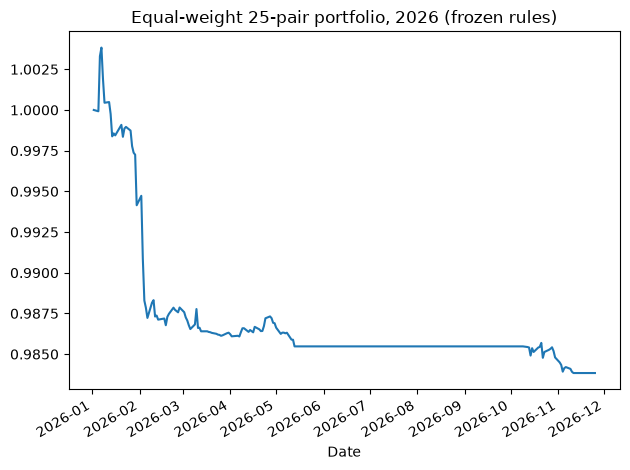

In [17]:
rows, rets26 = [], {}
for r in pairs_df.itertuples():
    name = f"{r.a}/{r.b}"
    ret, pos = walk_forward(px_all, r.a, r.b, lookback=LOOKBACK)
    r26 = ret.loc["2026-01-01":]
    rets26[name] = r26
    s_ = stats(r26, pos)
    rows.append(dict(pair=name, sharpe=s_["sharpe"], ret=s_["ret"],
                     maxdd=s_["maxdd"], trades=s_["trades"], in_mkt=s_["in_mkt"]))

res26 = pd.DataFrame(rows).set_index("pair")
res26.to_csv(os.path.join(PROJECT, "pair_scan_results_2026.csv"))
print(res26.round(2).to_string())

t26 = res26[res26.trades > 0]
print(f"\n2026: {len(t26)} of {len(res26)} pairs traded")
print(f"Median Sharpe (traded pairs): {t26.sharpe.median():.2f} | Positive: {(t26.sharpe > 0).sum()} of {len(t26)}")

port26 = pd.DataFrame(rets26).fillna(0).mean(axis=1)
eq26 = (1 + port26).cumprod()
sh26 = port26.mean() / port26.std() * np.sqrt(252) if port26.std() > 0 else np.nan
print(f"Portfolio Sharpe {sh26:.2f} | return {eq26.iloc[-1]-1:.2%} | maxDD {(eq26/eq26.cummax()-1).min():.2%}")
eq26.plot(title="Equal-weight 25-pair portfolio, 2026 (frozen rules)")
save_fig("portfolio_2026"); plt.show()